# 04 · Explore bedbug reports and evictions
| Dataset | What it is | For the renter |
|---|---|---|
| [Bedbug Reporting](https://data.cityofnewyork.us/d/wz6d-d3jb) | Landlords of 3+ unit buildings must file **yearly**: units, infested units, eradicated, re-infested | "This building had bedbugs in 2 of the last 3 years" |
| [Evictions](https://data.cityofnewyork.us/d/6z8x-wfk4) | Evictions executed by NYC marshals, by address | A signal of landlord behavior (Q2) |

**Study window: January 1, 2025–October 31, 2026.** Annual comparisons should use January–October in both years. Housing prediction uses six-month histories and four-month outcomes; older figures and reports describe the previous study.

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from src import config, housing as H, preprocess as P
from src.plots import save, ACCENT, MUTED

pd.set_option("display.float_format", "{:,.2f}".format)
pd.set_option("display.max_colwidth", 80)

pluto = H.clean_pluto_table()[["bbl", "is_residential", "unitsres", "yearbuilt"]]   # cleans PLUTO on first use
pluto_bbls = set(pluto["bbl"])
residential_bbls = set(pluto.loc[pluto["is_residential"], "bbl"])

## Part A: Bedbugs

In [2]:
bb = H.load("bedbugs")
print(f"{len(bb):,} filings")
H.overview(bb)

118,012 filings


,missing_%,distinct,example
building_id,0.00,110855,299422
registration_id,0.00,110833,821665
borough,0.00,5,BROOKLYN
house_number,0.00,14546,451
street_name,0.00,3804,GATES AVENUE
postcode,0.00,185,11216
of_dwelling_units,0.00,615,2
infested_dwelling_unit_count,0.00,33,0
eradicated_unit_count,0.00,73,0
re_infested_dwelling_unit,0.00,17,0


In [3]:
for col in ["of_dwelling_units", "infested_dwelling_unit_count", "eradicated_unit_count", "re_infested_dwelling_unit"]:
    bb[col] = pd.to_numeric(bb[col], errors="coerce")
bb["period_end"] = pd.to_datetime(bb["filling_period_end_date"].astype(str), errors="coerce")
bb["year"] = bb["period_end"].dt.year
yearly = bb[bb["period_end"].dt.month <= 10].groupby("year").agg(filings=("bbl", "size"), buildings=("bbl", "nunique"),
                                with_infestation=("infested_dwelling_unit_count", lambda s: (s > 0).mean()),
                                infested_units=("infested_dwelling_unit_count", "sum"),
                                units=("of_dwelling_units", "sum"))
yearly["infested_per_1000_units"] = yearly.infested_units / yearly.units * 1000
yearly

,filings,buildings,with_infestation,infested_units,units,infested_per_1000_units
year,,,,,,
2025,118012,103092,0.03,421798,3126928,134.89


In [4]:
# Data quality: impossible values
print("Infested > units:", (bb.infested_dwelling_unit_count > bb.of_dwelling_units).sum())
print("Negative counts:", (bb[["infested_dwelling_unit_count", "eradicated_unit_count"]] < 0).any(axis=1).sum())
print(f"BBL match to PLUTO: {H.coverage(bb['bbl'], pluto_bbls):.1%}")
print(f"Filings per building per year (duplicates?): {bb.groupby(['bbl', 'year']).size().gt(1).mean():.1%} have >1")

Infested > units: 0
Negative counts: 0


BBL match to PLUTO: 99.8%
Filings per building per year (duplicates?): 8.0% have >1


In [5]:
# Preview of Q1 for bedbugs: infested one year → infested the next?
inf = bb[bb.infested_dwelling_unit_count > 0][["bbl", "year"]].dropna()
last_two = sorted(inf.year.dropna().unique())[-2:]
if len(last_two) < 2:
    print("Only one filing-period year is available before the study cutoff; a two-year recurrence comparison is unavailable.")
else:
    filed = bb[bb.year.isin(last_two)].groupby("bbl")["year"].nunique().eq(2)
    both_years = set(filed[filed].index)                       # buildings that filed in both years
    y1, y2 = last_two
    had = set(inf[inf.year == y1].bbl) & both_years
    again = set(inf[inf.year == y2].bbl) & both_years
    p_again = len(had & again) / len(had)
    p_new = len(again - had) / len(both_years - had)
    print(f"Of buildings infested in {y1:.0f}, {p_again:.0%} were infested again in {y2:.0f}; "
          f"of buildings clean in {y1:.0f}, {p_new:.1%} became infested ({p_again / p_new:.0f}x difference)")

Only one filing-period year is available before the study cutoff; a two-year recurrence comparison is unavailable.


## Part B: Evictions

In [6]:
ev = H.load("evictions")
print(f"{len(ev):,} evictions")
display(H.overview(ev))
ev["executed_date"] = pd.to_datetime(ev["executed_date"].astype(str), errors="coerce")
ev["year"] = ev["executed_date"].dt.year
pd.crosstab(ev.loc[ev["executed_date"].dt.month <= 10, "year"], ev.loc[ev["executed_date"].dt.month <= 10, "residential_commercial_ind"])

34,816 evictions


,missing_%,distinct,example
court_index_number,0.00,31703,300435/25
docket_number,0.00,33402,24441
eviction_address,0.00,22892,967 KELLY STREET APT. 6C
eviction_apt_num,12.00,5183,6C
executed_date,0.00,427,2026-10-14T00:00:00.000
marshal_first_name,0.00,19,Robert
marshal_last_name,0.00,20,Renzulli
residential_commercial_ind,0.00,4,Residential
borough,0.00,8,BRONX
eviction_zip,0.00,209,10459


residential_commercial_ind,C,Commercial,R,Residential
year,,,,
2025,1,1293,9,15435
2026,33,1049,301,14129


In [7]:
res = ev[ev["residential_commercial_ind"].astype(str).str.upper().str.startswith("RES")]
print(f"Residential evictions: {len(res):,}; with BBL: {res['bbl'].notna().mean():.1%}; "
      f"BBL match to PLUTO: {H.coverage(res['bbl'], pluto_bbls):.1%}")
per_bldg = res.dropna(subset=["bbl"]).groupby("bbl").size()
display(H.concentration(per_bldg).map("{:.0%}".format).to_frame("share of evictions").T)
per_bldg.sort_values(ascending=False).head(10).to_frame("evictions (all years)")

Residential evictions: 31,905; with BBL: 93.3%; BBL match to PLUTO: 97.8%


,top 1%,top 5%,top 10%
share of evictions,11%,25%,35%


,evictions (all years)
bbl,
4159260001,138
2028820229,118
2051410120,110
4156100001,90
4124950002,80
2039447501,69
2039437501,66
4031750001,45
4099980091,43


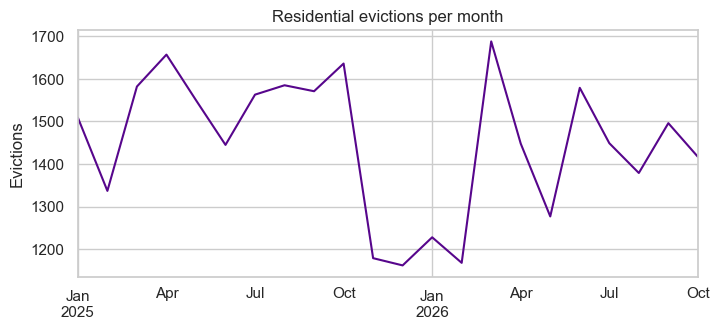

In [8]:
fig, ax = plt.subplots(figsize=(8, 3.2))
res.groupby(res["executed_date"].dt.to_period("M")).size().plot(ax=ax, color=ACCENT)
ax.set(title="Residential evictions per month", xlabel="", ylabel="Evictions")
save(fig, "rent04a_evictions_per_month")

## Findings

Run the cells above to inspect results for the shared January 2025–October 2026 study. Previous-window metrics are not reused.